In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
import pandas as pd

df = pd.read_csv("customer_segmentation_dataset.csv")

df.head()

,CustomerID,Gender,Age,Annual_Income_k,Spending_Score
0,1,Female,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Male,23,16,77
4,5,Female,31,17,40


In [13]:
df.tail()

,CustomerID,Gender,Age,Annual_Income_k,Spending_Score
25,26,Female,39,42,61
26,27,Male,31,44,22
27,28,Female,28,46,84
28,29,Male,43,48,12
29,30,Female,24,50,55


In [14]:
df.shape

(30, 5)

In [15]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual_Income_k', 'Spending_Score'], dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   CustomerID       30 non-null     int64 
 1   Gender           30 non-null     object
 2   Age              30 non-null     int64 
 3   Annual_Income_k  30 non-null     int64 
 4   Spending_Score   30 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 1.3+ KB


In [17]:
df.describe()

,CustomerID,Age,Annual_Income_k,Spending_Score
count,30.000000,30.000000,30.000000,30.000000
mean,15.500000,30.000000,27.966667,48.100000
std,8.803408,7.239737,10.701219,28.123312
min,1.000000,19.000000,15.000000,6.000000
25%,8.250000,24.000000,19.250000,20.500000
50%,15.500000,29.500000,25.500000,49.500000
75%,22.750000,35.000000,35.500000,75.250000
max,30.000000,45.000000,50.000000,94.000000


In [18]:
df.isnull().sum()

CustomerID         0
Gender             0
Age                0
Annual_Income_k    0
Spending_Score     0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.dtypes

CustomerID          int64
Gender             object
Age                 int64
Annual_Income_k     int64
Spending_Score      int64
dtype: object

# DATA CLEANING & UNDERSTANDING

# Age Distribution

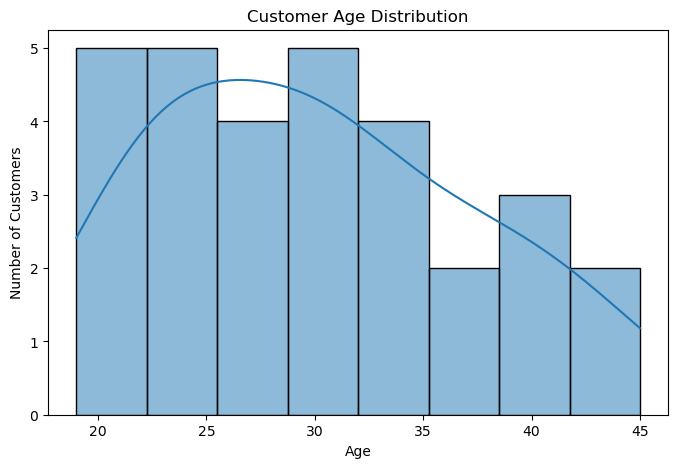

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(df['Age'], bins=8, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

# Annual income distribution

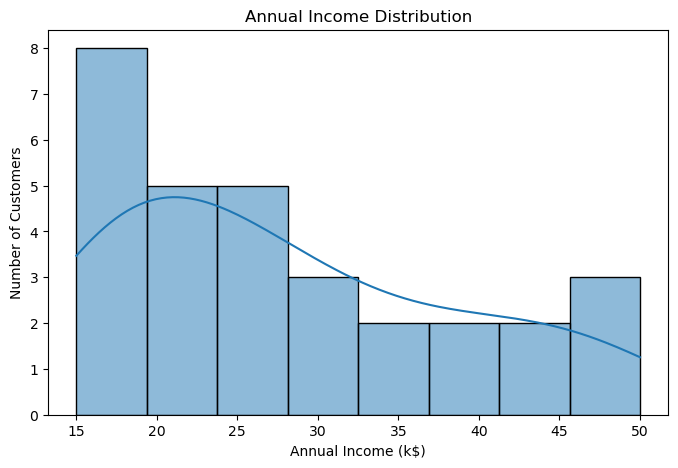

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(df['Annual_Income_k'], bins=8, kde=True)

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')
plt.show()

# Spending Score Distribution

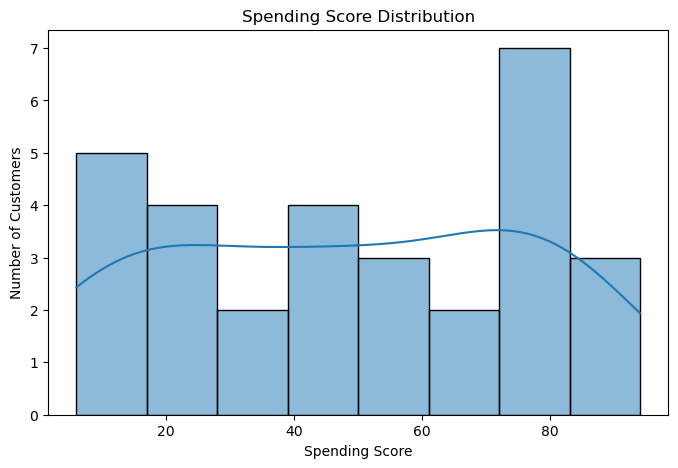

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(df['Spending_Score'], bins=8, kde=True)

plt.title('Spending Score Distribution')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')
plt.show()

# Age vs  Spending Score

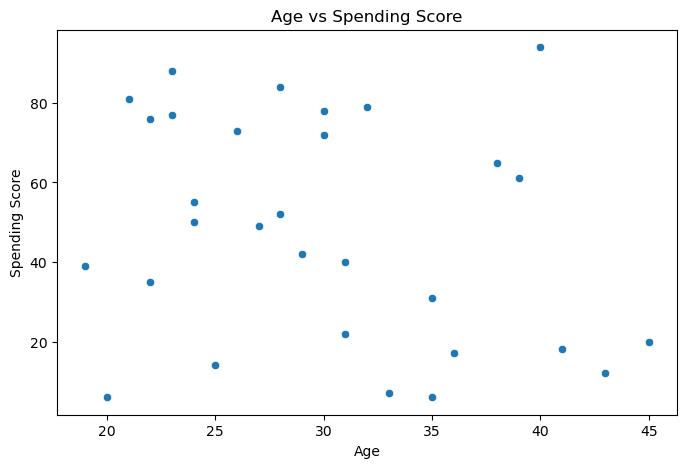

In [24]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Spending_Score'
)

plt.title('Age vs Spending Score')
plt.xlabel('Age')
plt.ylabel('Spending Score')
plt.show()

# Income vs Spending Score

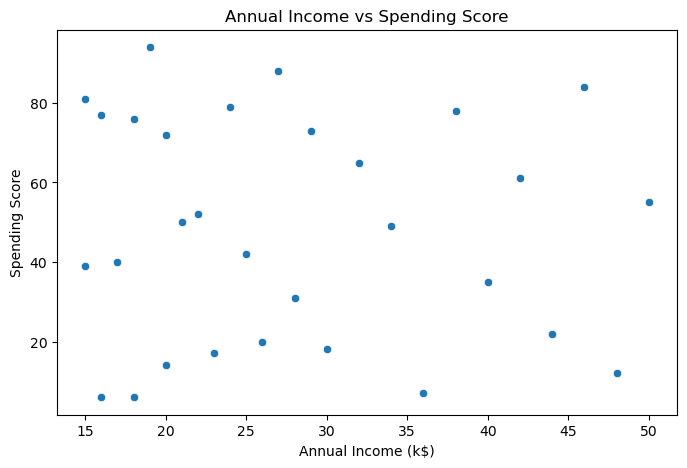

In [25]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score'
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.show()

# Gender Distribution

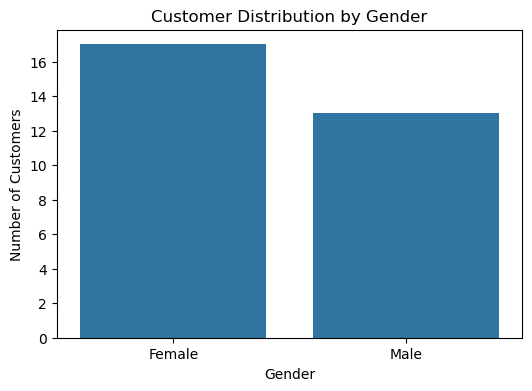

In [26]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

In [27]:
X = df[['Age', 'Annual_Income_k', 'Spending_Score']]

In [28]:
X.head()

,Age,Annual_Income_k,Spending_Score
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


# Feature Scaling + Elbow Method

In [29]:
from sklearn.preprocessing import StandardScaler

In [30]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [31]:
X_scaled[:5]

array([[-1.54536659, -1.23241426, -0.32910657],
       [-1.26439085, -1.23241426,  1.18984683],
       [-1.40487872, -1.13736946, -1.52256996],
       [-0.9834151 , -1.13736946,  1.0451846 ],
       [ 0.14048787, -1.04232466, -0.29294101]])

In [33]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

C:\Users\ANIKA AANYA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ANIKA AANYA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ANIKA AANYA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ANIKA AANYA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have

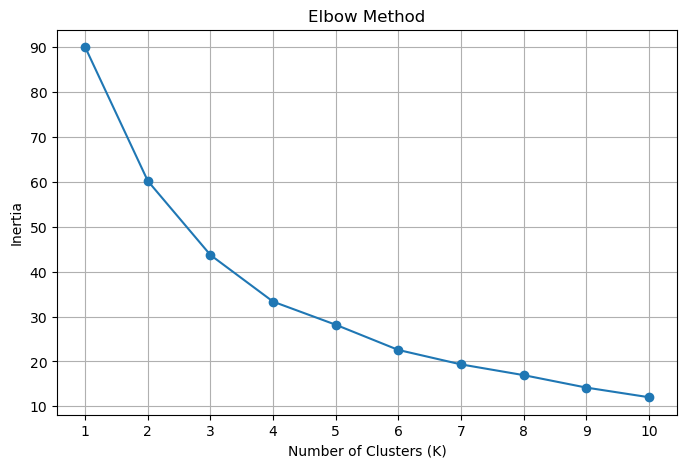

In [34]:
plt.figure(figsize=(8,5))

plt.plot(range(1, 11), inertia, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

# K-Means Model

In [35]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Model Train Karo

In [36]:
cluster_labels = kmeans.fit_predict(X_scaled)

C:\Users\ANIKA AANYA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [37]:
cluster_labels

array([3, 0, 3, 0, 3, 0, 1, 0, 0, 3, 3, 3, 1, 0, 3, 1, 0, 1, 0, 1, 2, 2,
       1, 2, 2, 2, 2, 2, 1, 2], dtype=int32)

# Cluster Column Dataset

In [38]:
df['Cluster'] = cluster_labels

In [39]:
df.head()

,CustomerID,Gender,Age,Annual_Income_k,Spending_Score,Cluster
0,1,Female,19,15,39,3
1,2,Male,21,15,81,0
2,3,Female,20,16,6,3
3,4,Male,23,16,77,0
4,5,Female,31,17,40,3


In [40]:
df['Cluster'].value_counts().sort_index()

Cluster
0    8
1    7
2    8
3    7
Name: count, dtype: int64

# Clusters Visualize

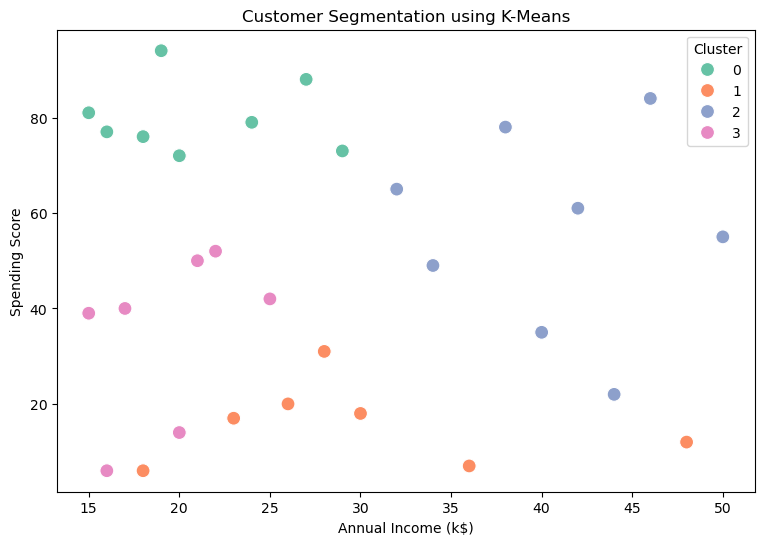

In [41]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Cluster',
    palette='Set2',
    s=100
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.legend(title='Cluster')

plt.show()

# Cluster Centers

In [42]:
cluster_centers = scaler.inverse_transform(kmeans.cluster_centers_)

cluster_centers_df = pd.DataFrame(
    cluster_centers,
    columns=['Age', 'Annual_Income_k', 'Spending_Score']
)

cluster_centers_df

,Age,Annual_Income_k,Spending_Score
0,27.125000,21.000000,80.000000
1,38.285714,29.857143,15.857143
2,29.875000,40.750000,56.125000
3,25.142857,19.428571,34.714286


# Customer Profiling

In [43]:
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual_Income_k', 'Spending_Score']
].mean()

cluster_summary

,Age,Annual_Income_k,Spending_Score
Cluster,,,
0,27.125000,21.000000,80.000000
1,38.285714,29.857143,15.857143
2,29.875000,40.750000,56.125000
3,25.142857,19.428571,34.714286


# Customer Count Per Cluster

In [44]:
cluster_counts = df['Cluster'].value_counts().sort_index()

cluster_counts

Cluster
0    8
1    7
2    8
3    7
Name: count, dtype: int64

In [45]:
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual_Income_k', 'mean'),
    Average_Spending_Score=('Spending_Score', 'mean')
).round(2)

cluster_summary

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,8,27.12,21.00,80.00
1,7,38.29,29.86,15.86
2,8,29.88,40.75,56.12
3,7,25.14,19.43,34.71


# Cluster Comparison — Income

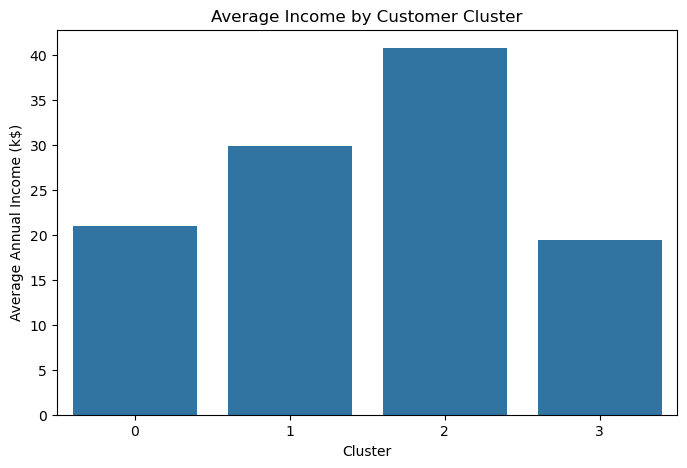

In [46]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary['Average_Income']
)

plt.title('Average Income by Customer Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Annual Income (k$)')

plt.show()

# Cluster Comparison — Spending

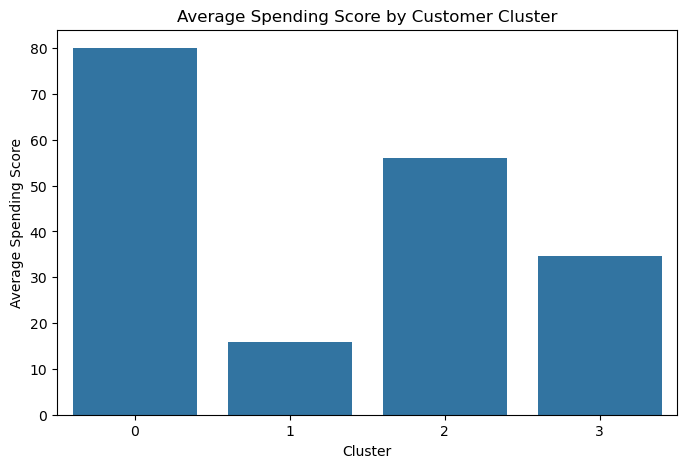

In [47]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary['Average_Spending_Score']
)

plt.title('Average Spending Score by Customer Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Spending Score')

plt.show()

# Final Customer Segments & Business Insights

In [48]:
cluster_summary

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,8,27.12,21.00,80.00
1,7,38.29,29.86,15.86
2,8,29.88,40.75,56.12
3,7,25.14,19.43,34.71


# Customer Segment Column

In [49]:
segment_names = {
    0: 'High-Value Customers',
    1: 'Potential Customers',
    2: 'Frequent Spenders',
    3: 'Low-Value Customers'
}

df['Customer_Segment'] = df['Cluster'].map(segment_names)

In [50]:
df[['CustomerID', 'Cluster', 'Customer_Segment']].head(10)

,CustomerID,Cluster,Customer_Segment
0,1,3,Low-Value Customers
1,2,0,High-Value Customers
2,3,3,Low-Value Customers
3,4,0,High-Value Customers
4,5,3,Low-Value Customers
5,6,0,High-Value Customers
6,7,1,Potential Customers
7,8,0,High-Value Customers
8,9,0,High-Value Customers
9,10,3,Low-Value Customers


# Final Segment Count

In [51]:
df['Customer_Segment'].value_counts()

Customer_Segment
High-Value Customers    8
Frequent Spenders       8
Low-Value Customers     7
Potential Customers     7
Name: count, dtype: int64

# Final Visualization

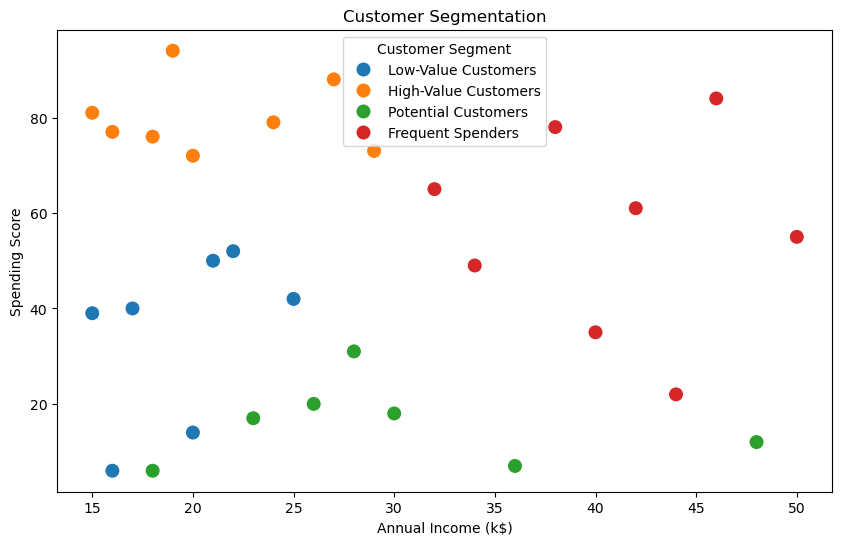

In [52]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Customer_Segment',
    s=120
)

plt.title('Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.legend(title='Customer Segment')

plt.show()

# Project Evaluation & Visualization

In [53]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(X_scaled, df['Cluster'])

print("Silhouette Score:", round(silhouette_avg, 3))

Silhouette Score: 0.283


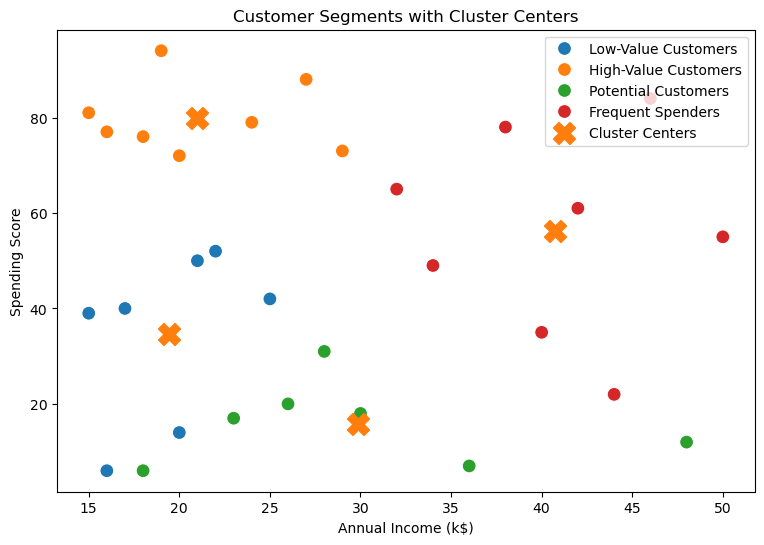

In [54]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Customer_Segment',
    s=100
)

plt.scatter(
    cluster_centers_df['Annual_Income_k'],
    cluster_centers_df['Spending_Score'],
    marker='X',
    s=250,
    label='Cluster Centers'
)

plt.title('Customer Segments with Cluster Centers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.legend()

plt.show()

In [55]:
df.to_csv('customer_segmentation_final.csv', index=False)

In [56]:
df.head()

,CustomerID,Gender,Age,Annual_Income_k,Spending_Score,Cluster,Customer_Segment
0,1,Female,19,15,39,3,Low-Value Customers
1,2,Male,21,15,81,0,High-Value Customers
2,3,Female,20,16,6,3,Low-Value Customers
3,4,Male,23,16,77,0,High-Value Customers
4,5,Female,31,17,40,3,Low-Value Customers
